# Full A-T CLN with element-local recovery

**Shared-trace solves plus element-local recovery reproduce the existing high-order A-T CLN. The earlier unconstrained one-pass curl sweep fails on the actual curved wire mesh.** Both outcomes are retained.

This study integrates recovery into every A and T solve of the unchanged [A-T recursion](../validation/cln3d/CLN_AT.py), then advances the CLN using the returned fields. It compares seven coefficients, all seven cumulative physical modes, original equation residuals and complete-run time. It reuses one mesh per cohort and identical order, conductor, boundary conditions, quadrature and normalization.

The direct one-pass variant constructs each local right hand side from the actual stage curl, without reading the target potential coefficients. Its recovered potential would drive the next stage. A failed recovery gate stops that variant; there is no fallback.

**Follow-up:** [Notebook 20](20_compatible_element_recovery.ipynb) diagnoses the frozen shared-DOF failure and records compatible iterative recovery in the complete high-order CLN. The experiments below retain their original methods and outcomes.

## Compatible integration

For element interior unknowns I and shared edge/face unknowns t, the original A-T equation is factored as

$$S u_t=f_t-K_{tI}K_{II}^{-1}f_I,\qquad S=K_{tt}-K_{tI}K_{II}^{-1}K_{It},$$
$$u_I=K_{II}^{-1}(f_I-K_{It}u_t).$$

NGSolve's [static condensation and local recovery](https://docu.ngsolve.org/latest/how_to/howto_staticcondensation.html) own these operations. The original compact HCurl spaces remove higher gradient basis modes. The remaining exact-gradient trace kernel is gauged, without physical mass perturbation. NGSolve sparsecholesky solves the global trace system. Every reconstructed field must pass the **uncondensed original A-T equation residual <1e-6**.

This is an exact factorization of the existing discrete A-T equations. The global unknowns here are traces. Biro/Koster's scalar-potential construction in [notebook 18](18_element_curl_recovery.ipynb) has global scalar corrections; the two algorithms are distinct. An independent one-pass curl recovery attempt is tested separately and rejected when incompatible.

In these compact tetrahedral spaces, p=2 has zero element-interior unknowns; p=3 has three per tetrahedron and p=4 has eleven. Thus p=2 is a useful control: any time change there cannot be attributed to eliminating interior unknowns.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if not (root/'validation').is_dir(): root=root.parent
data=json.loads((root/'docs/data/element_cln_study.json').read_text())
print(data['runtime'])
print(data['scope'])
print(data['timing_protocol'])
print('p h[mm] tetrahedra max coefficient difference max volume-field difference max original residual')
for c in data['cohorts']:
    comparisons=[r for r in c['comparisons'] if r['route']=='condensed']
    coefficient=max(max(abs(np.array(r['relative_coefficients']))) for r in comparisons)
    field=max(max(r['volume_relative_field_errors']) for r in comparisons)
    residual=max(s['original_rhs_residual'] for r in c['repeats'] if r['route']=='condensed' for s in r['solves'])
    print(c['order'],1e3*c['maxh'],c['ne'],f'{coefficient:.3e}',f'{field:.3e}',f'{residual:.3e}')

{'host': 'intel11', 'python': '3.12.10', 'ngsolve': '6.2.2607', 'numpy': '2.5.2', 'radia': '5.2.3', 'threads': 4}
Internal round wire, zero shift, identical A-T spaces and recursion; trace coupling stays global
First observed run and three subsequent complete runs per route in one process; alternating route order; setup and verification included; no mesh generation or comparison/postprocessing time; not process cold-start latency
p h[mm] tetrahedra max coefficient difference max volume-field difference max original residual
2 3.0 510 5.145e-12 6.049e-10 2.570e-14
3 3.0 510 1.924e-11 7.389e-10 3.099e-14
3 2.0 1510 4.921e-12 8.122e-10 7.462e-14
4 3.0 510 3.765e-11 8.153e-10 3.445e-14


## Timing controls

Four complete runs per route alternate execution order. The first observed run includes in-process initialization; it is not an interpreter/process cold-start measurement. The median of the following three runs describes warmed execution. Every run rebuilds its spaces and factors; factor reuse is only between CLN stages within that run.

- Original: the published sparsesolv ICCG workflow, including its per-stage setup.
- Full Cholesky: original uncondensed equations, same sparsecholesky backend and within-run two-factor reuse as the condensed route.
- Condensed: global trace solve and NGSolve element-local recovery.

Measured time includes matrix/load assembly, setup, all seven solves and original-equation residual verification. Mesh generation, cross-route field comparisons, saved field sampling and JSON serialization are excluded. The common recursion still assembles full matrices for residual verification; these are not timings of a matrix-free production implementation. Failed one-pass attempts stop early and are excluded from successful full-run speed comparisons.

p h[mm] route | first run [s] | subsequent median [s] | median setup [s]
2 3.0 original 0.9882 0.7747 0.0000
3 3.0 original 2.0640 2.0394 0.0000
3 2.0 original 6.0068 5.9941 0.0000
4 3.0 original 5.9237 5.9051 0.0000
2 3.0 full-cholesky 0.5842 0.6367 0.0919
3 3.0 full-cholesky 1.5718 1.5903 0.2793
3 2.0 full-cholesky 4.8089 4.6518 0.8310
4 3.0 full-cholesky 3.4667 3.4853 0.7303
2 3.0 condensed 0.5585 0.6210 0.0997
3 3.0 condensed 1.5932 1.5012 0.2258
3 2.0 condensed 4.4790 4.5283 0.7407
4 3.0 condensed 3.3331 3.2665 0.5498


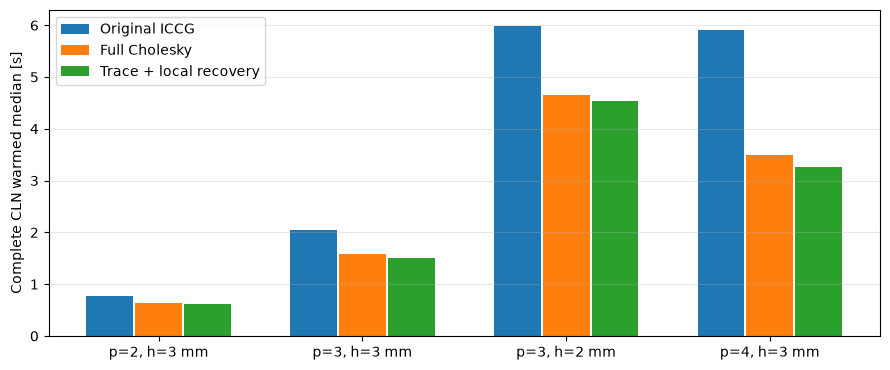

In [2]:
routes=['original','full-cholesky','condensed']
labels=['Original ICCG','Full Cholesky','Trace + local recovery']
print('p h[mm] route | first run [s] | subsequent median [s] | median setup [s]')
fig,ax=plt.subplots(figsize=(9,3.8))
x=np.arange(len(data['cohorts']))
for j,(route,label) in enumerate(zip(routes,labels)):
    medians=[]
    for c in data['cohorts']:
        rows=[r for r in c['repeats'] if r['route']==route and r['status']=='pass']
        first=next(r['seconds'] for r in rows if r['repeat']==0)
        median=np.median([r['seconds'] for r in rows if r['repeat']>0])
        setup=np.median([r['setup_seconds'] for r in rows if r['repeat']>0])
        medians.append(median)
        print(c['order'],1e3*c['maxh'],route,f'{first:.4f}',f'{median:.4f}',f'{setup:.4f}')
    ax.bar(x+(j-1)*.24,medians,width=.23,label=label)
ax.set_xticks(x,[f"p={c['order']}, h={1e3*c['maxh']:g} mm" for c in data['cohorts']])
ax.set_ylabel('Complete CLN warmed median [s]');ax.legend();ax.grid(axis='y',alpha=.3)
fig.tight_layout();plt.show()

The condensed route agrees with the original across all cohorts: maximum coefficient difference **3.77e-11**, volume vector-field difference **8.16e-10**, and original-equation residual **7.47e-14**. At p=4, warmed medians are 5.905 s (original ICCG), 3.485 s (full Cholesky) and 3.266 s (trace/local). The 1.81x change against the original includes backend and factor reuse. Against the matched Cholesky control, the observed p=3/4 time reduction is about 3-6%. Three subsequent runs on one host do not establish general performance superiority.

## Compare fields and energies

We compare vector differences integrated over the entire 3D conductor, not only magnitudes or potentials. Fields are E0, B1, E2, B3, E4, B5, E6. Saved 78-point vector samples provide an independently checkable spatial comparison. The portable gate also recomputes every coefficient from its saved field-energy integral: R=1/(sigma integral |E|^2), L=(integral |B|^2)/mu.

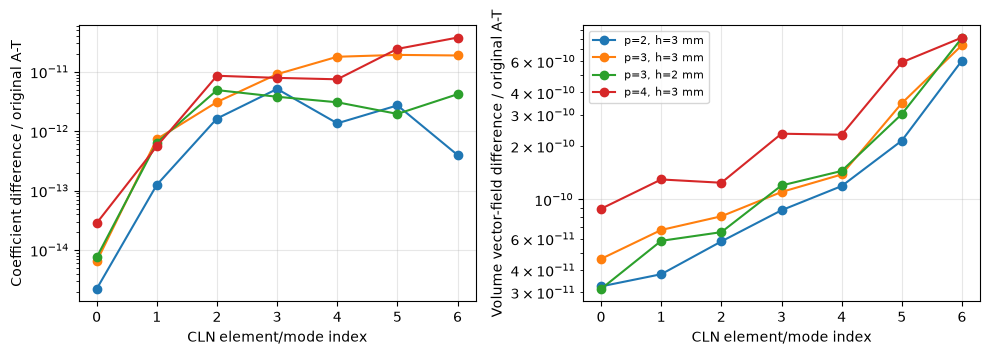

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
for c in data['cohorts']:
    rows=[r for r in c['comparisons'] if r['route']=='condensed']
    coefficients=np.max(np.abs([r['relative_coefficients'] for r in rows]),axis=0)
    fields=np.max([r['volume_relative_field_errors'] for r in rows],axis=0)
    label=f"p={c['order']}, h={1e3*c['maxh']:g} mm"
    axes[0].semilogy(range(7),np.maximum(coefficients,1e-16),'o-',label=label)
    axes[1].semilogy(range(7),np.maximum(fields,1e-16),'o-',label=label)
axes[0].set_ylabel('Coefficient difference / original A-T')
axes[1].set_ylabel('Volume vector-field difference / original A-T')
for ax in axes: ax.set_xlabel('CLN element/mode index');ax.grid(alpha=.3)
axes[1].legend(fontsize=8);fig.tight_layout();plt.show()

## Why the earlier sweep is not sufficient

The 12-tetrahedron affine cube test showed that a local minimum-residual sweep can recover compatible high-order curls for those mesh traversals. On the actual curved CLN wire, the failure is consistent with fixing shared potential coefficients before later-element compatibility conditions have been imposed. Compatibility of the prescribed curl alone does not guarantee success of that greedy traversal. This study demonstrates failure; it does not prove a unique cause or impossibility of all one-pass algorithms.

The rejected variants never advance with a changed field. The compatible trace/local route keeps shared degrees of freedom in the global solve and reconstructs only the independent element interiors afterward.

In [4]:
print('p h[mm] failed stage | curl fit residual | physical curl-field error | completed solves')
for c in data['cohorts']:
    r=next(r for r in c['repeats'] if r['route']=='condensed+sweep' and r['repeat']==0)
    if r['status']=='rejected':
        f=r['failure_diagnostics']
        print(c['order'],1e3*c['maxh'],r['failed_stage'],f"{f['curl_fit_residual']:.4f}",f"{f['relative_curl_field_error']:.4f}",r['completed_solves'])
    else: print(c['order'],1e3*c['maxh'],'passed')

p h[mm] failed stage | curl fit residual | physical curl-field error | completed solves
2 3.0 T stage 0 2.0149 2.0149 0
3 3.0 T stage 0 2.1085 2.1085 0
3 2.0 T stage 0 2.5326 2.5326 0
4 3.0 T stage 0 2.1795 2.1795 0


## Scope and reproduction

Verified scope is linear internal round-wire A-T, zero expansion point, p=2/3/4, three stages, geometry curve order 3 and bonus quadrature 8. These tests preserve the previously established A-T coefficient accuracy in that scope; they add no general claim about terminal accuracy or other formulations. Positive shifts, nonlinear materials, air, nontrivial topology and a scalar-potential CLN with a provably compatible one-pass inverse remain separate research gates.

[Integration adapter](../validation/cln3d/element_recovery.py), [complete study producer](../validation/element_cln_study.py), [native results](data/element_cln_study.json), [portable gate](../validation/validate_element_cln_study.py).

```text
python validation/element_cln_study.py --output docs/data/element_cln_study.json
python validation/validate_element_cln_study.py
```

Native runs use the recorded LAB interpreter, NGSolve and Radia versions. Portable CI checks source identity, coverage, coefficient/field/energy parity, equation residuals, timing structure, explicit failures and five corrupted-evidence controls.